# Overview of the Results

This notebook gives a first overview of the results of the experiment.

The process consists of:
1. **Summary**: Counting the model runs per size category and operating mode, with the range of their results.
2. **Accuracy vs. Energy**: Plotting every model run by its accuracy and GPU energy per question.
3. **Pareto Front**: Listing the model runs on the Pareto front and finding its knee.
4. **Standout Models**: Identifying the model runs with the highest and lowest values.
5. **Total Energy**: Computing the energy consumed by each model run over its 10 repetitions.
6. **Repeatability**: Measuring the variation between the 10 repetitions of each model run.
7. **Sampling Uncertainty**: Estimating confidence intervals from the sample of 372 questions.
8. **Key Values**: Printing the main values of this notebook.

The Mistral models are not included yet (`PENDING_FAMILIES` in `common.py`).

### Setup & Imports
We load the tables built by `00-dataset.ipynb` and the chart helpers of `common.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import (
    CATEGORY_ORDER,
    FAMILY_ORDER,
    PENDING_FAMILIES,
    QUESTIONS,
    bootstrap_questions,
    chance_level,
    legend_handles,
    load_inferences,
    load_model_runs,
    load_questions,
    load_repetitions,
    pareto_front,
    save_chart,
    scatter_model_runs,
    short_name,
)

model_runs = load_model_runs()
repetitions = load_repetitions(model_runs)
questions = load_questions(model_runs)
inferences = load_inferences(model_runs)

CHANCE_LEVEL = chance_level(questions)
FAMILIES = [family for family in FAMILY_ORDER if family in set(model_runs["family"])]

print(f"Families left out for now: {PENDING_FAMILIES}")
print(f"Model runs: {len(model_runs)}   models: {model_runs['model'].nunique()}   repetitions: {len(repetitions)}   inferences: {len(inferences)}")
print(f"Chance level of the benchmark sample: {CHANCE_LEVEL:.3f}")

Families left out for now: ['Mistral']
Model runs: 47   models: 41   repetitions: 470   inferences: 174840
Chance level of the benchmark sample: 0.114


### 1. Summary of the Model Runs
Number of model runs in each size category and operating mode, with the range of their accuracy, GPU energy per question and generated tokens per question.

In [2]:
def low_high(values, digits):
    return f"{values.min():.{digits}f} to {values.max():.{digits}f}"


summary = model_runs.groupby(["category", "mode"]).apply(
    lambda group: pd.Series({
        "Model runs": len(group),
        "Accuracy": low_high(group["accuracy"], 2),
        "GPU energy per question (J)": low_high(group["gpu_joules_per_question"], 0),
        "Generated tokens per question": low_high(group["generated_tokens_per_question"], 0),
    }),
    include_groups=False,
)
summary.reindex(CATEGORY_ORDER, level="category")

Model runs      Accuracy  \
category         mode                                  
Tiny/Mobile      Instruct           12  0.18 to 0.74   
                 Reasoning           5  0.39 to 0.74   
Small/Edge       Instruct           14  0.24 to 0.79   
                 Reasoning           4  0.70 to 0.76   
Standard/Desktop Instruct            9  0.27 to 0.71   
                 Reasoning           3  0.74 to 0.78   

                           GPU energy per question (J)  \
category         mode                                    
Tiny/Mobile      Instruct                  184 to 3127   
                 Reasoning               3975 to 15791   
Small/Edge       Instruct                  674 to 4671   
                 Reasoning               7414 to 27291   
Standard/Desktop Instruct                  444 to 3422   
                 Reasoning              24329 to 27390   

                           Generated tokens per question  
category         mode                                     
Tiny/Mobile      Instruct                      80 to 814  
                 Reasoning                  1858 to 4103  
Small/Edge       Instruct                      91 to 669  
                 Reasoning                  1708 to 3920  
Standard/Desktop Instruct                     159 to 310  
                 Reasoning                  2031 to 2257

### 2. Accuracy vs. GPU Energy per Question
We plot every model run by its GPU energy per question (log scale) and its accuracy. Colour gives the size category, marker shape the family, and reasoning runs are drawn hollow. The grey line is the Pareto front, whose model runs are labelled, and the horizontal line is the chance level.

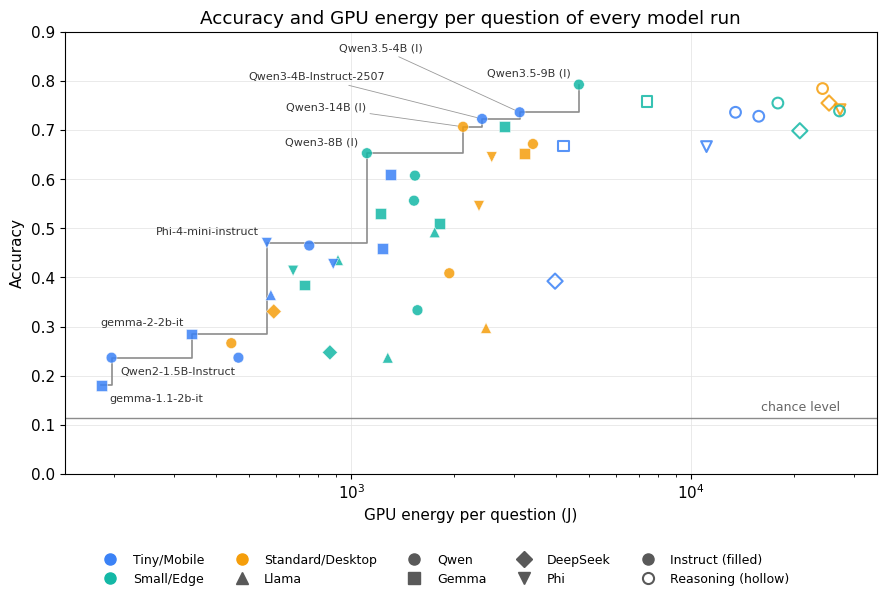

In [3]:
front = pareto_front(model_runs, "gpu_joules_per_question", "accuracy")

fig, ax = plt.subplots(figsize=(9, 6))
ax.axhline(CHANCE_LEVEL, color="0.55", linewidth=1)
ax.text(model_runs["gpu_joules_per_question"].max(), CHANCE_LEVEL + 0.008, "chance level", ha="right", va="bottom", color="0.4", fontsize=9)
ax.plot(front["gpu_joules_per_question"], front["accuracy"], drawstyle="steps-post", color="0.55", linewidth=1.2, zorder=1)
scatter_model_runs(ax, model_runs, "gpu_joules_per_question", "accuracy", zorder=2)

# Labels of the model runs on the front, moved aside where the points are close together
OFFSETS = {
    "gemma-1.1-2b-it": (6, -12),
    "Qwen2-1.5B-Instruct": (6, -12),
    "Qwen3-14B (I)": (-70, 14),
    "Qwen3-4B-Instruct-2507": (-70, 30),
    "Qwen3.5-4B (I)": (-70, 46),
}
for _, run in front.iterrows():
    name = short_name(run["model_run"])
    dx, dy = OFFSETS.get(name, (-6, 6))
    ax.annotate(
        name,
        (run["gpu_joules_per_question"], run["accuracy"]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="left" if dx > 0 else "right",
        va="center" if abs(dx) > 20 else "baseline",
        fontsize=8,
        color="0.2",
        arrowprops=dict(arrowstyle="-", color="0.6", linewidth=0.6, shrinkA=1, shrinkB=4) if abs(dx) > 20 else None,
    )

ax.set_xscale("log")
ax.set_ylim(0, 0.9)
ax.set_xlabel("GPU energy per question (J)")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy and GPU energy per question of every model run")
fig.legend(handles=legend_handles(families=FAMILIES), loc="lower center", ncol=5, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.09, 1, 1))
save_chart(fig, "overview-accuracy-energy")
plt.show()

### 3. Pareto Front and Knee
We list the model runs on the Pareto front, for which no other run is both cheaper and more accurate. The knee is the point of the front farthest from the line joining its two ends, with the energy on a log scale and both axes scaled to the range of the front.

In [4]:
front = front.copy()
x = np.log10(front["gpu_joules_per_question"])
x = (x - x.min()) / (x.max() - x.min())
y = (front["accuracy"] - front["accuracy"].min()) / (front["accuracy"].max() - front["accuracy"].min())
# Distance of each point to the line from (0, 0) to (1, 1)
front["distance_to_chord"] = (y - x) / np.sqrt(2)
knee = front.loc[front["distance_to_chord"].idxmax()]

front_table = front[["model_run", "category", "mode", "release_date", "accuracy", "gpu_joules_per_question", "correct_answers_per_kj", "distance_to_chord"]].copy()
front_table["release_date"] = front_table["release_date"].dt.date
print(f"Model runs on the Pareto front: {len(front)} of {len(model_runs)}   reasoning runs among them: {(front['mode'] == 'Reasoning').sum()}")
print(f"Knee of the front: {knee['model_run']}")
front_table.round({"accuracy": 3, "gpu_joules_per_question": 0, "correct_answers_per_kj": 3, "distance_to_chord": 3}).reset_index(drop=True)

Model runs on the Pareto front: 9 of 47   reasoning runs among them: 0
Knee of the front: Qwen/Qwen3-8B (Instruct Mode)


,model_run,category,mode,release_date,accuracy,gpu_joules_per_question,correct_answers_per_kj,distance_to_chord
0,google/gemma-1.1-2b-it,Tiny/Mobile,Instruct,2024-03-26,0.180,184.0,0.988,0.000
1,Qwen/Qwen2-1.5B-Instruct,Tiny/Mobile,Instruct,2024-06-03,0.237,197.0,1.210,0.050
2,google/gemma-2-2b-it,Tiny/Mobile,Instruct,2024-07-16,0.285,339.0,0.835,-0.013
3,microsoft/Phi-4-mini-instruct,Tiny/Mobile,Instruct,2025-02-19,0.470,564.0,0.833,0.090
4,Qwen/Qwen3-8B (Instruct Mode),Small/Edge,Instruct,2025-04-27,0.653,1111.0,0.588,0.153
5,Qwen/Qwen3-14B (Instruct Mode),Standard/Desktop,Instruct,2025-04-27,0.707,2131.0,0.332,0.072
6,Qwen/Qwen3-4B-Instruct-2507,Tiny/Mobile,Instruct,2025-08-05,0.723,2425.0,0.298,0.063
7,Qwen/Qwen3.5-4B (Instruct Mode),Tiny/Mobile,Instruct,2026-02-27,0.737,3127.0,0.236,0.023
8,Qwen/Qwen3.5-9B (Instruct Mode),Small/Edge,Instruct,2026-02-27,0.793,4671.0,0.170,0.000


### 4. Standout Models
Most accurate, least and most energy per question, most correct answers per kJ, the knee of the front, and the most accurate model run under each energy budget.

In [5]:
def describe(run):
    return {
        "Model run": short_name(run["model_run"]),
        "Category": run["category"],
        "Accuracy": round(run["accuracy"], 3),
        "GPU energy per question (J)": round(run["gpu_joules_per_question"]),
        "Correct answers per kJ": round(run["correct_answers_per_kj"], 3),
    }


BUDGETS_KJ = [0.5, 1, 2, 5]

headline = {
    "Most accurate": model_runs.loc[model_runs["accuracy"].idxmax()],
    "Least energy per question": model_runs.loc[model_runs["gpu_joules_per_question"].idxmin()],
    "Most energy per question": model_runs.loc[model_runs["gpu_joules_per_question"].idxmax()],
    "Most correct answers per kJ": model_runs.loc[model_runs["correct_answers_per_kj"].idxmax()],
    "Knee of the Pareto front": knee,
}
for budget in BUDGETS_KJ:
    affordable = model_runs[model_runs["gpu_joules_per_question"] <= budget * 1000]
    headline[f"Most accurate under {budget:g} kJ per question"] = affordable.loc[affordable["accuracy"].idxmax()]

pd.DataFrame({title: describe(run) for title, run in headline.items()}).T

,Model run,Category,Accuracy,GPU energy per question (J),Correct answers per kJ
Most accurate,Qwen3.5-9B (I),Small/Edge,0.793,4671,0.17
Least energy per question,gemma-1.1-2b-it,Tiny/Mobile,0.18,184,0.988
Most energy per question,Phi-4-reasoning,Standard/Desktop,0.742,27390,0.027
Most correct answers per kJ,Qwen2-1.5B-Instruct,Tiny/Mobile,0.237,197,1.21
Knee of the Pareto front,Qwen3-8B (I),Small/Edge,0.653,1111,0.588
Most accurate under 0.5 kJ per question,gemma-2-2b-it,Tiny/Mobile,0.285,339,0.835
Most accurate under 1 kJ per question,Phi-4-mini-instruct,Tiny/Mobile,0.47,564,0.833
Most accurate under 2 kJ per question,Qwen3-8B (I),Small/Edge,0.653,1111,0.588
Most accurate under 5 kJ per question,Qwen3.5-9B (I),Small/Edge,0.793,4671,0.17


### 5. Total Energy per Model Run
GPU energy consumed by each model run over its 10 repetitions (3,720 inferences), and its split between operating modes.

In [6]:
totals = model_runs.assign(total_gpu_kwh=model_runs["total_gpu_joules"] / 3.6e6, inference_hours=model_runs["total_inference_seconds"] / 3600)
most = totals.loc[totals["total_gpu_kwh"].idxmax()]
least = totals.loc[totals["total_gpu_kwh"].idxmin()]
print(f"Most GPU energy over its 10 repetitions:  {short_name(most['model_run'])}: {most['total_gpu_kwh']:.1f} kWh in {most['inference_hours']:.1f} hours of inference")
print(f"Least GPU energy over its 10 repetitions: {short_name(least['model_run'])}: {least['total_gpu_kwh']:.2f} kWh in {least['inference_hours']:.2f} hours of inference")
print(f"Ratio between the two: {most['total_gpu_kwh'] / least['total_gpu_kwh']:.0f} times")

by_mode = totals.groupby("mode")[["total_gpu_kwh", "inference_hours"]].sum()
by_mode["share of the GPU energy (%)"] = 100 * by_mode["total_gpu_kwh"] / by_mode["total_gpu_kwh"].sum()
by_mode.round(1)

Most GPU energy over its 10 repetitions:  Phi-4-reasoning: 28.3 kWh in 93.2 hours of inference
Least GPU energy over its 10 repetitions: gemma-1.1-2b-it: 0.19 kWh in 0.69 hours of inference
Ratio between the two: 149 times


,total_gpu_kwh,inference_hours,share of the GPU energy (%)
mode,,,
Instruct,55.6,188.7,21.3
Reasoning,205.8,690.2,78.7


### 6. Repeatability
We compute the coefficient of variation, between the 10 repetitions of each model run, of the total GPU energy and of the GPU energy per generated token. A model run is deterministic when it generates the same number of tokens for every question in all repetitions.

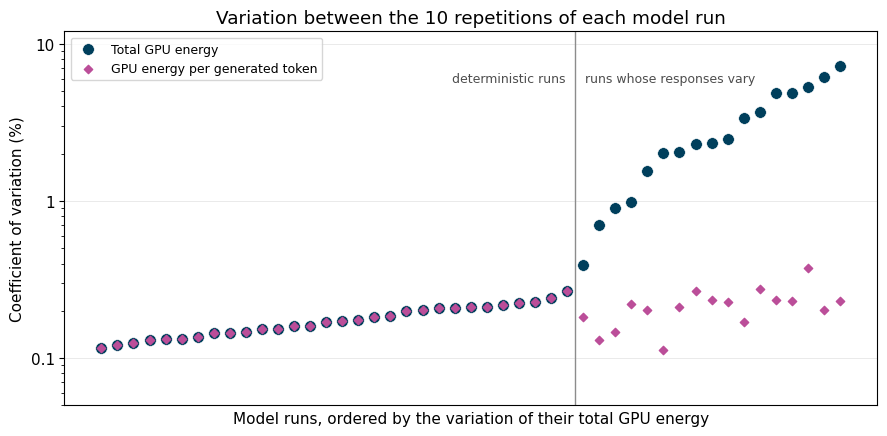

Deterministic model runs: 30 of 47
              energy_cv       tokens_cv       energy_per_token_cv       accuracy_range      
                 median   max    median   max              median   max         median   max
deterministic                                                                               
False              2.33  7.25      2.33  7.15                0.22  0.37           3.76  6.72
True               0.17  0.27      0.00  0.00                0.17  0.27           0.00  0.00


In [7]:
def variation(values):
    return 100 * values.std(ddof=1) / values.mean()


tokens_per_question = inferences.groupby(["model_run", "question_id"])["generated_tokens"].nunique()
deterministic = (tokens_per_question == 1).groupby("model_run").all()

repeatability = repetitions.groupby("model_run").agg(
    energy_cv=("total_inference_gpu_joules", variation),
    tokens_cv=("total_generated_tokens", variation),
    energy_per_token_cv=("gpu_joules_per_generated_token", variation),
    accuracy_range=("avg_accuracy", lambda values: 100 * (values.max() - values.min())),
)
repeatability["deterministic"] = deterministic
repeatability = repeatability.sort_values("energy_cv").reset_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(repeatability))
ax.scatter(positions, repeatability["energy_cv"], s=70, color="#003f5c", edgecolors="w", linewidth=0.4, label="Total GPU energy")
ax.scatter(positions, repeatability["energy_per_token_cv"], s=18, color="#bb4e99", marker="D", label="GPU energy per generated token")
boundary = repeatability["deterministic"].sum() - 0.5
ax.axvline(boundary, color="0.55", linewidth=1)
ax.text(boundary - 0.6, 6, "deterministic runs", ha="right", va="center", fontsize=9, color="0.3")
ax.text(boundary + 0.6, 6, "runs whose responses vary", ha="left", va="center", fontsize=9, color="0.3")
ax.set_yscale("log")
ax.set_ylim(0.05, 12)
ax.set_yticks([0.1, 1, 10], labels=["0.1", "1", "10"])
ax.set_xticks([])
ax.set_xlabel("Model runs, ordered by the variation of their total GPU energy")
ax.set_ylabel("Coefficient of variation (%)")
ax.set_title("Variation between the 10 repetitions of each model run")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
save_chart(fig, "overview-repeatability")
plt.show()

assert repeatability["deterministic"].iloc[: repeatability["deterministic"].sum()].all()

print(f"Deterministic model runs: {repeatability['deterministic'].sum()} of {len(repeatability)}")
print(repeatability.groupby("deterministic")[["energy_cv", "tokens_cv", "energy_per_token_cv", "accuracy_range"]].agg(["median", "max"]).round(2).to_string())

### 7. Sampling Uncertainty
We estimate the 95% confidence interval of the accuracy and of the GPU energy per question of each model run with a bootstrap over the 372 questions, stratified by subject.

In [8]:
rows = []
for model_run, run_questions in questions.groupby("model_run"):
    resampled = bootstrap_questions(run_questions, ["correct", "gpu_joules_mean"])
    accuracy_low, accuracy_high = np.percentile(resampled["correct"], [2.5, 97.5])
    energy_low, energy_high = np.percentile(resampled["gpu_joules_mean"], [2.5, 97.5])
    energy = run_questions["gpu_joules_mean"].mean()
    rows.append({
        "model_run": model_run,
        "accuracy": run_questions["correct"].mean(),
        "accuracy_low": accuracy_low,
        "accuracy_high": accuracy_high,
        "accuracy_half_width_points": 100 * (accuracy_high - accuracy_low) / 2,
        "energy_low": energy_low,
        "energy_high": energy_high,
        "energy_half_width_percent": 100 * (energy_high - energy_low) / 2 / energy,
    })
intervals = pd.DataFrame(rows)

print("Half-width of the 95% interval, over the model runs:")
print(intervals[["accuracy_half_width_points", "energy_half_width_percent"]].describe().loc[["min", "50%", "max"]].round(1).to_string())

Half-width of the 95% interval, over the model runs:
     accuracy_half_width_points  energy_half_width_percent
min                         2.7                        4.0
50%                         4.4                        7.6
max                         5.0                       14.8


### 8. Key Values

In [9]:
most_accurate = headline["Most accurate"]
cheapest = headline["Least energy per question"]
costliest = headline["Most energy per question"]
efficient = headline["Most correct answers per kJ"]

print(f"Model runs analysed: {len(model_runs)} ({(model_runs['mode'] == 'Instruct').sum()} instruct, {(model_runs['mode'] == 'Reasoning').sum()} reasoning), from {model_runs['model'].nunique()} models")
print(f"Accuracy: {model_runs['accuracy'].min():.3f} to {model_runs['accuracy'].max():.3f} ({model_runs['accuracy'].max() / model_runs['accuracy'].min():.1f} times)")
print(f"GPU energy per question: {model_runs['gpu_joules_per_question'].min():.0f} J to {model_runs['gpu_joules_per_question'].max():.0f} J ({model_runs['gpu_joules_per_question'].max() / model_runs['gpu_joules_per_question'].min():.0f} times)")
print(f"Most accurate: {short_name(most_accurate['model_run'])} ({most_accurate['accuracy']:.3f}, {most_accurate['gpu_joules_per_question']:.0f} J per question)")
print(f"Least energy per question: {short_name(cheapest['model_run'])} ({cheapest['gpu_joules_per_question']:.0f} J, accuracy {cheapest['accuracy']:.3f})")
print(f"Most energy per question: {short_name(costliest['model_run'])} ({costliest['gpu_joules_per_question']:.0f} J, accuracy {costliest['accuracy']:.3f})")
print(f"Most correct answers per kJ: {short_name(efficient['model_run'])} ({efficient['correct_answers_per_kj']:.2f}, accuracy {efficient['accuracy']:.3f})")
print(f"Pareto front: {len(front)} model runs, {(front['mode'] == 'Reasoning').sum()} of them reasoning runs; knee: {short_name(knee['model_run'])}")
ranks = model_runs[["correct_answers_per_kj", "accuracy", "gpu_joules_per_question"]].rank()
print(f"Rank correlation of accuracy per joule with accuracy: {ranks['correct_answers_per_kj'].corr(ranks['accuracy']):.2f}; with energy per question: {ranks['correct_answers_per_kj'].corr(ranks['gpu_joules_per_question']):.2f}")
print(f"Deterministic model runs: {repeatability['deterministic'].sum()} of {len(repeatability)}")
print(f"Variation of total GPU energy between repetitions: median {repeatability['energy_cv'].median():.2f}%, maximum {repeatability['energy_cv'].max():.2f}%")
print(f"Variation of GPU energy per generated token: median {repeatability['energy_per_token_cv'].median():.2f}%, maximum {repeatability['energy_per_token_cv'].max():.2f}%")
print(f"95% interval from the question sample: accuracy ±{intervals['accuracy_half_width_points'].median():.1f} points (median), energy per question ±{intervals['energy_half_width_percent'].median():.0f}% (median)")

Model runs analysed: 47 (35 instruct, 12 reasoning), from 41 models
Accuracy: 0.180 to 0.793 (4.4 times)
GPU energy per question: 184 J to 27390 J (149 times)
Most accurate: Qwen3.5-9B (I) (0.793, 4671 J per question)
Least energy per question: gemma-1.1-2b-it (184 J, accuracy 0.180)
Most energy per question: Phi-4-reasoning (27390 J, accuracy 0.742)
Most correct answers per kJ: Qwen2-1.5B-Instruct (1.21, accuracy 0.237)
Pareto front: 9 model runs, 0 of them reasoning runs; knee: Qwen3-8B (I)
Rank correlation of accuracy per joule with accuracy: -0.66; with energy per question: -0.95
Deterministic model runs: 30 of 47
Variation of total GPU energy between repetitions: median 0.21%, maximum 7.25%
Variation of GPU energy per generated token: median 0.18%, maximum 0.37%
95% interval from the question sample: accuracy ±4.4 points (median), energy per question ±8% (median)
